# Überblick über eBL- und Oracc-Korpora

Dieses Notebook wertet die drei bereitgestellten Dateien `daten/ebl_korpus_manuskripte.jsonl.gz`, `daten/ebl_korpus.jsonl.gz` und `daten/oracc.jsonl.gz` aus und prüft die Größenordnung des eBL-Fragmentariums zusätzlich über die öffentliche eBL-API. Die lokalen eBL-Dateien enthalten Kapitelrekonstruktionen und zugehörige Manuskriptbelege, **nicht den vollständigen Fragmentbestand der eBL-Library**. Ihre Datensatz-, Text- und Wortzahlen dürfen daher nicht als Gesamtzahlen der Library gelesen werden.

Eine **Komposition** entspricht einem eindeutigen Wert in `text`; eine **Zeile** ist ein JSONL-Datensatz. Ein **Wort** gilt als annotiert, wenn `lemma` mindestens einen Eintrag enthält. Bei Oracc zählen damit auch mehrdeutige Lemma-Kandidaten als annotiert; der Zuordnungsstatus wird zusätzlich separat aufgeschlüsselt. Eine Zeile gilt als vollständig annotiert, wenn sie mindestens ein Wort enthält und jedes Wort ein Lemma hat. Manuskriptzahlen werden nur für Quellen mit einem `manuskript`-Feld ausgewiesen. Für die Manuskripte zählen Perioden eindeutige Manuskripte und Gattungen eindeutige Texte je Gattungskürzel.

Die API-Werte sind **Fragmente, transliterierte Fragmente und Zeilen**, nicht Kompositionen, Worttoken oder Lemma-Anteile. Der verlinkte Datensatzartikel beschreibt eine frühere Datenfassung (Stand 2023: etwa 25.000 Tafeln und über 350.000 transliterierte Zeilen); aktuelle Zahlen werden bei jedem Lauf direkt von der API gelesen.

## API-Prüfung

Der folgende API-Aufruf zeigt den aktuellen Bestand des eBL-Fragmentariums. Diese Werte betreffen Fragmente und Zeilen des gesamten Fragmentkatalogs, nicht Kompositionen, Manuskripte oder Wörter der beiden lokalen eBL-Korpusdateien. Der API-Endpunkt stellt keine Wort- oder Lemma-Zahlen bereit.

Der Datensatzartikel [Cobanoglu et al. (2024)](https://doi.org/10.5334/johd.148) beschreibt eine Datenfassung von 2023 und ist kein aktueller Zähler. Die folgende Zelle ruft die API-Werte bei jedem Lauf neu ab.

## Kennzahlen im Vergleich

| Datenquelle | Kompositionen | Manuskripte | Wörter gesamt | Wörter mit Lemma | Anteil Wörter mit Lemma | Vollständig annotierte Zeilen | Anteil vollständige Zeilen | Zeilen gesamt |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| eBL-Manuskripte | 223 | 1.924 | 387.066 | 123.286 | 31,85 % | 11.293 | 21,71 % | 52.018 |
| eBL-Rekonstruktion | 159 | nicht ausgewiesen | 67.929 | 66.781 | 98,31 % | 13.330 | 95,24 % | 13.996 |
| Oracc | 7.081 | nicht ausgewiesen | 891.439 | 507.558 | 56,94 % | 49.799 | 30,30 % | 164.356 |

## eBL-Manuskripte: Perioden und Gattungen

Perioden: eindeutige Manuskripte; Gattungen: eindeutige Texte je im Datensatz hinterlegtem Kürzel.

### Perioden

| Periode | Manuskripte |
| --- | --- |
| Neo-Assyrian | 1027 |
| Neo-Babylonian | 426 |
| Late Babylonian | 266 |
| Old Babylonian | 95 |
| Middle Babylonian | 37 |
| Hellenistic | 33 |
| Middle Assyrian | 21 |
| Persian | 13 |
| None | 7 |
| Parthian | 4 |
| Hittite | 3 |
| Uncertain | 1 |

### Gattungen

| Gattungskürzel | Texte |
| --- | --- |
| L | 108 |
| D | 53 |
| Mag | 51 |
| Šui | 8 |
| Lex | 1 |
| Med | 1 |
| Sum | 1 |

### Oracc-Zuordnungsstatus

Eindeutige, mehrdeutige und fehlende Lemma-Zuordnungen:

| Zuordnungsstatus | Wörter | Anteil an Oracc-Wörtern |
| --- | --- | --- |
| eindeutig | 507.432 | 56,92 % |
| keine | 383.881 | 43,06 % |
| mehrdeutig | 126 | 0,01 % |

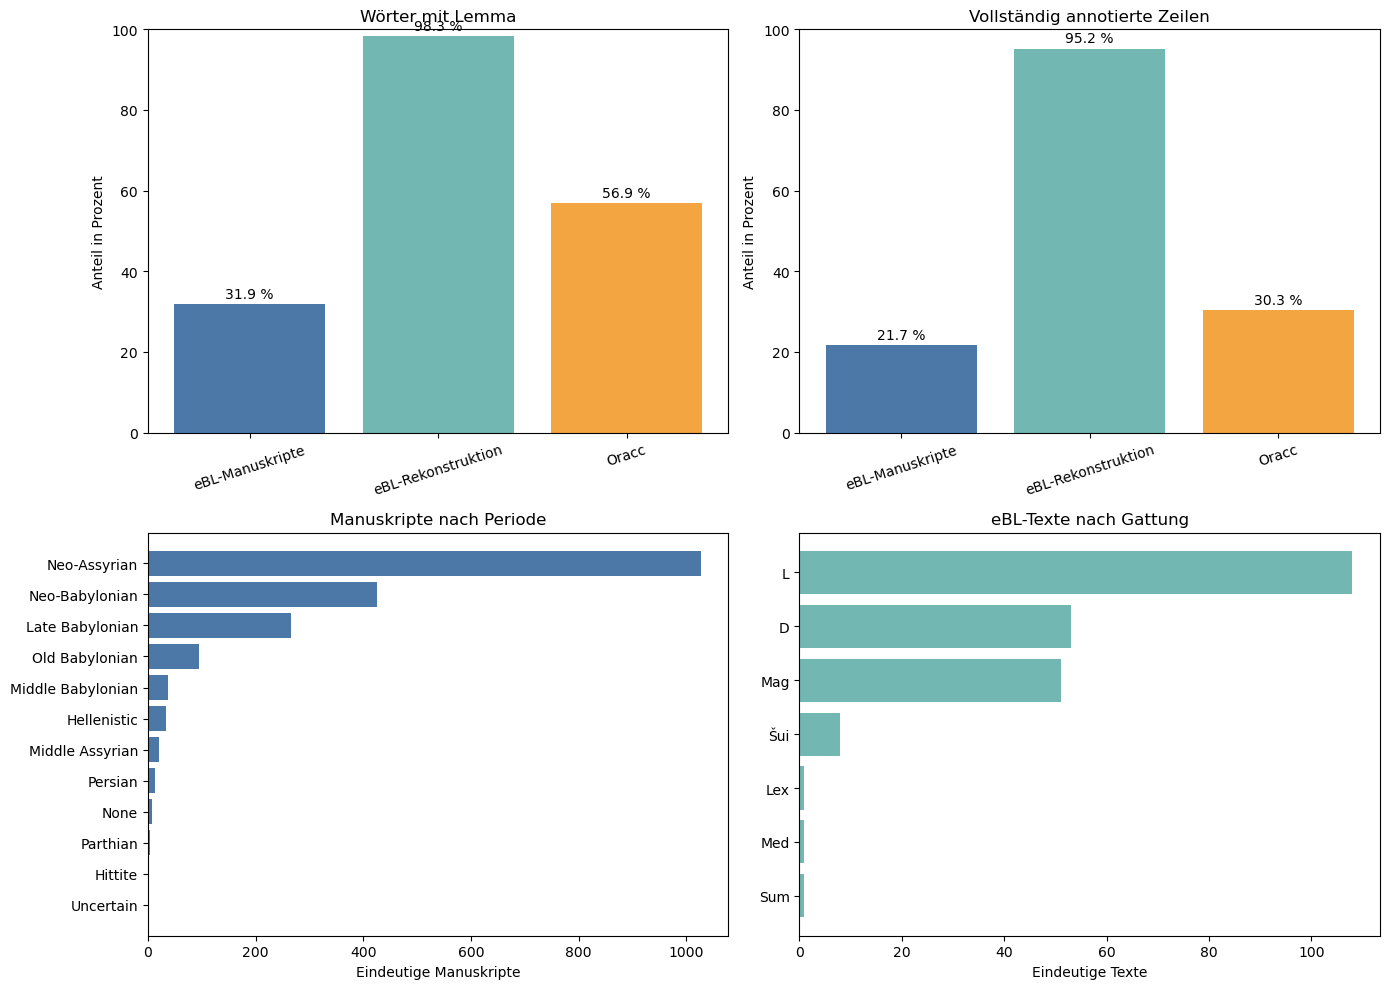

In [7]:
import gzip
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DATA_DIR = Path('daten')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('..') / 'daten'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Der Ordner daten wurde im Arbeitsverzeichnis nicht gefunden.')

DATASETS = {
    'eBL-Manuskripte': DATA_DIR / 'ebl_korpus_manuskripte.jsonl.gz',
    'eBL-Rekonstruktion': DATA_DIR / 'ebl_korpus.jsonl.gz',
    'Oracc': DATA_DIR / 'oracc.jsonl.gz',
}

stats = {}
period_manuscripts = defaultdict(set)
genre_texts = defaultdict(set)
oracc_mappings = defaultdict(int)

for source, path in DATASETS.items():
    if not path.is_file():
        raise FileNotFoundError('Datendatei nicht gefunden: {}'.format(path))

    result = {
        'zeilen': 0,
        'kompositionen': set(),
        'manuskripte': set(),
        'woerter': 0,
        'annotierte_woerter': 0,
        'vollstaendig_annotierte_zeilen': 0,
    }

    with gzip.open(path, 'rt', encoding='utf-8') as file:
        for line in file:
            record = json.loads(line)
            result['zeilen'] += 1

            text = record.get('text')
            if text:
                result['kompositionen'].add(text)

            manuscript = record.get('manuskript')
            if manuscript:
                result['manuskripte'].add(manuscript)
                period = record.get('periode') or 'Nicht angegeben'
                period_manuscripts[period].add(manuscript)

            if source == 'eBL-Manuskripte' and text:
                genres = record.get('gattung') or []
                if isinstance(genres, str):
                    genres = [genres]
                for genre in genres:
                    if genre:
                        genre_texts[genre].add(text)

            words = record.get('woerter') or []
            annotated = [bool(word.get('lemma')) for word in words]
            result['woerter'] += len(words)
            result['annotierte_woerter'] += sum(annotated)
            result['vollstaendig_annotierte_zeilen'] += int(bool(words) and all(annotated))

            if source == 'Oracc':
                for word in words:
                    status = word.get('zuordnung') or 'Nicht angegeben'
                    oracc_mappings[status] += 1

    result['kompositionen'] = len(result['kompositionen'])
    result['manuskripte'] = len(result['manuskripte']) if result['manuskripte'] else None
    stats[source] = result


def percent(part, whole):
    return 100 * part / whole if whole else 0


def format_count(value):
    return format(value, ',').replace(',', '.')


def markdown_table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join('---' for _ in headers) + ' |']
    lines.extend('| ' + ' | '.join(str(value) for value in row) + ' |' for row in rows)
    return chr(10).join(lines)


summary_rows = []
for source, result in stats.items():
    manuscript_count = result['manuskripte']
    manuscript_count = format_count(manuscript_count) if manuscript_count is not None else 'nicht ausgewiesen'
    summary_rows.append([
        source,
        format_count(result['kompositionen']),
        manuscript_count,
        format_count(result['woerter']),
        format_count(result['annotierte_woerter']),
        '{:.2f} %'.format(percent(result['annotierte_woerter'], result['woerter'])).replace('.', ','),
        format_count(result['vollstaendig_annotierte_zeilen']),
        '{:.2f} %'.format(percent(result['vollstaendig_annotierte_zeilen'], result['zeilen'])).replace('.', ','),
        format_count(result['zeilen']),
    ])

summary_headers = [
    'Datenquelle', 'Kompositionen', 'Manuskripte', 'Wörter gesamt', 'Wörter mit Lemma',
    'Anteil Wörter mit Lemma', 'Vollständig annotierte Zeilen', 'Anteil vollständige Zeilen', 'Zeilen gesamt',
]
display(Markdown('## Kennzahlen im Vergleich' + chr(10) + chr(10) + markdown_table(summary_headers, summary_rows)))

period_rows = [
    (period, len(manuscripts))
    for period, manuscripts in sorted(period_manuscripts.items(), key=lambda item: (-len(item[1]), item[0]))
]
genre_rows = [
    (genre, len(texts))
    for genre, texts in sorted(genre_texts.items(), key=lambda item: (-len(item[1]), item[0]))
]

display(Markdown(
    '## eBL-Manuskripte: Perioden und Gattungen' + chr(10) + chr(10)
    + 'Perioden: eindeutige Manuskripte; Gattungen: eindeutige Texte je im Datensatz hinterlegtem Kürzel.'
))
display(Markdown('### Perioden' + chr(10) + chr(10) + markdown_table(['Periode', 'Manuskripte'], period_rows)))
display(Markdown('### Gattungen' + chr(10) + chr(10) + markdown_table(['Gattungskürzel', 'Texte'], genre_rows)))

display(Markdown('### Oracc-Zuordnungsstatus' + chr(10) + chr(10) + 'Eindeutige, mehrdeutige und fehlende Lemma-Zuordnungen:'))
oracc_rows = [
    (status, format_count(count), '{:.2f} %'.format(percent(count, stats['Oracc']['woerter'])).replace('.', ','))
    for status, count in sorted(oracc_mappings.items(), key=lambda item: (-item[1], item[0]))
]
display(Markdown(markdown_table(['Zuordnungsstatus', 'Wörter', 'Anteil an Oracc-Wörtern'], oracc_rows)))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sources = list(stats)
word_rates = [percent(stats[source]['annotierte_woerter'], stats[source]['woerter']) for source in sources]
line_rates = [percent(stats[source]['vollstaendig_annotierte_zeilen'], stats[source]['zeilen']) for source in sources]

axes[0, 0].bar(sources, word_rates, color=['#4C78A8', '#72B7B2', '#F2A541'])
axes[0, 0].set_title('Wörter mit Lemma')
axes[0, 0].set_ylabel('Anteil in Prozent')
axes[0, 0].set_ylim(0, 100)
axes[0, 0].tick_params(axis='x', rotation=18)
for index, value in enumerate(word_rates):
    axes[0, 0].text(index, value + 1.5, '{:.1f} %'.format(value), ha='center')

axes[0, 1].bar(sources, line_rates, color=['#4C78A8', '#72B7B2', '#F2A541'])
axes[0, 1].set_title('Vollständig annotierte Zeilen')
axes[0, 1].set_ylabel('Anteil in Prozent')
axes[0, 1].set_ylim(0, 100)
axes[0, 1].tick_params(axis='x', rotation=18)
for index, value in enumerate(line_rates):
    axes[0, 1].text(index, value + 1.5, '{:.1f} %'.format(value), ha='center')

period_labels = [row[0] for row in period_rows]
period_counts = [row[1] for row in period_rows]
axes[1, 0].barh(period_labels[::-1], period_counts[::-1], color='#4C78A8')
axes[1, 0].set_title('Manuskripte nach Periode')
axes[1, 0].set_xlabel('Eindeutige Manuskripte')

genre_labels = [row[0] for row in genre_rows]
genre_counts = [row[1] for row in genre_rows]
axes[1, 1].barh(genre_labels[::-1], genre_counts[::-1], color='#72B7B2')
axes[1, 1].set_title('eBL-Texte nach Gattung')
axes[1, 1].set_xlabel('Eindeutige Texte')

fig.tight_layout()
plt.show()

## Abgleich mit der aktuellen eBL-API

Abrufdatum: **2026-10-30** · Quelle: [öffentlicher eBL-API-Endpunkt](https://www.ebl.lmu.de/api/statistics)

| API-Kennzahl | Aktueller Wert |
| --- | --- |
| Einträge im eBL-Fragmentkatalog | 328.922 |
| Davon transliterierte Fragmente | 38.739 |
| Zeilen laut eBL-API | 629.591 |

**Einordnung:** Die zuvor ausgewiesenen 223 Kompositionen und 1.924 Manuskripte stammen aus `ebl_korpus_manuskripte.jsonl.gz`; sie beschreiben die dort enthaltenen Kapitel und Belege, nicht die gesamte Library. Die API weist für den gesamten Fragmentkatalog Fragmente und Zeilen aus. Sie liefert über `/statistics` keine Worttoken- oder Lemma-Zahlen; deshalb lassen sich die Wort- und Annotationsanteile nicht auf die vollständige eBL-Library hochrechnen. Der Artikel [Cobanoglu et al. (2024)](https://doi.org/10.5334/johd.148) beschreibt eine ältere Datenfassung und ist kein aktueller Zähler.

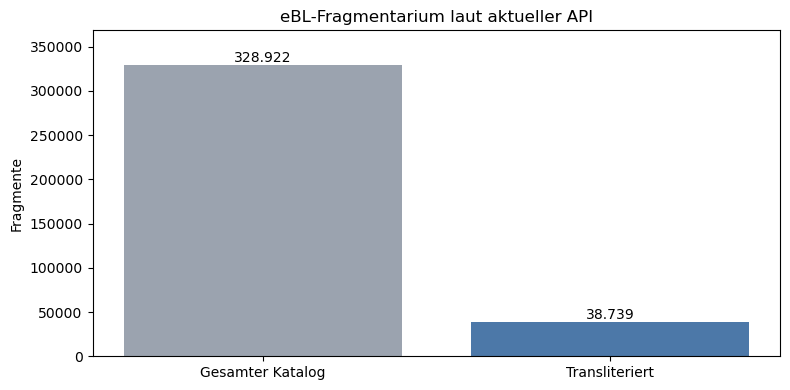

In [3]:
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.request import urlopen

EBL_API_STATS_URL = 'https://www.ebl.lmu.de/api/statistics'
with urlopen(EBL_API_STATS_URL, timeout=30) as response:
    api_stats = json.loads(response.read().decode('utf-8'))

required_api_fields = {'totalFragments', 'transliteratedFragments', 'lines'}
missing_api_fields = required_api_fields.difference(api_stats)
if missing_api_fields:
    raise ValueError('Die eBL-API-Antwort enthält nicht die erwarteten Felder: {}'.format(sorted(missing_api_fields)))

api_rows = [
    ('Einträge im eBL-Fragmentkatalog', format_count(api_stats['totalFragments'])),
    ('Davon transliterierte Fragmente', format_count(api_stats['transliteratedFragments'])),
    ('Zeilen laut eBL-API', format_count(int(api_stats['lines']))),
]
display(Markdown(
    '## Abgleich mit der aktuellen eBL-API' + chr(10) + chr(10)
    + 'Abrufdatum: **{}** · Quelle: [öffentlicher eBL-API-Endpunkt]({})'.format(datetime.now(ZoneInfo('Europe/Berlin')).date().isoformat(), EBL_API_STATS_URL)
    + chr(10) + chr(10)
    + markdown_table(['API-Kennzahl', 'Aktueller Wert'], api_rows)
))

display(Markdown(
    '**Einordnung:** Die zuvor ausgewiesenen 223 Kompositionen und 1.924 Manuskripte stammen aus '
    '`ebl_korpus_manuskripte.jsonl.gz`; sie beschreiben die dort enthaltenen Kapitel und Belege, '
    'nicht die gesamte Library. Die API weist für den gesamten Fragmentkatalog Fragmente und Zeilen aus. '
    'Sie liefert über `/statistics` keine Worttoken- oder Lemma-Zahlen; deshalb lassen sich die '
    'Wort- und Annotationsanteile nicht auf die vollständige eBL-Library hochrechnen. '
    'Der Artikel [Cobanoglu et al. (2024)](https://doi.org/10.5334/johd.148) beschreibt eine ältere '
    'Datenfassung und ist kein aktueller Zähler.'
))

fig_api, ax_api = plt.subplots(figsize=(8, 4))
api_fragment_labels = ['Gesamter Katalog', 'Transliteriert']
api_fragment_values = [api_stats['totalFragments'], api_stats['transliteratedFragments']]
ax_api.bar(api_fragment_labels, api_fragment_values, color=['#9BA3AF', '#4C78A8'])
ax_api.set_title('eBL-Fragmentarium laut aktueller API')
ax_api.set_ylabel('Fragmente')
for index, value in enumerate(api_fragment_values):
    ax_api.text(index, value, format_count(value), ha='center', va='bottom')
ax_api.set_ylim(0, max(api_fragment_values) * 1.12)
fig_api.tight_layout()
plt.show()